- Inclusão de EDA
- Inclusão de Feature Selection

# 1.0 Imports

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Silencia so uma categoria (ex: avisos de depreciacao)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Silencia so os warnings de uma lib especifica (ex: sklearn/lightgbm)
warnings.filterwarnings("ignore", module="sklearn")


In [83]:
from pathlib import Path

import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import preprocessing as pp
from sklearn import metrics as mt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import VarianceThreshold
import sklearn.ensemble as en

from scipy import stats
from scipy.stats import gaussian_kde
from scipy.stats import pointbiserialr
from scipy.stats import chi2_contingency

from boruta import BorutaPy

import xgboost as xgb
from lightgbm import LGBMClassifier

# 2.0 Loading Data

In [5]:
# Sobe a partir da pasta atual ate encontrar a raiz do projeto (onde esta pyproject.toml)
def project_root(start: Path = Path.cwd()) -> Path:
    for parent in [start, *start.parents]:
        if (parent / "pyproject.toml").exists():
            return parent
    raise FileNotFoundError("Raiz do projeto (pyproject.toml) nao encontrada")

ROOT = project_root()
DATA_PATH = ROOT / "data" / "HR-Employee-Attrition-balanced.csv"

df_raw = pd.read_csv(DATA_PATH)
df_raw

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,58,Yes,Travel_Rarely,601,Research & Development,7,4,Medical,1,1360,...,4,80,0,31,0,2,10,9,5,9
1,27,Yes,Travel_Frequently,1341,Human Resources,21,2,Human Resources,1,1950,...,1,80,0,0,2,3,0,0,0,0
2,50,Yes,Travel_Rarely,407,Sales,28,3,Marketing,1,2049,...,2,80,1,19,3,2,2,2,1,0
3,39,No,Non-Travel,439,Research & Development,9,3,Life Sciences,1,1132,...,3,80,0,9,2,2,5,4,0,3
4,32,No,Travel_Rarely,601,Sales,7,5,Marketing,1,1446,...,3,80,1,7,3,2,4,3,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1756,35,No,Travel_Rarely,750,Research & Development,28,3,Life Sciences,1,1596,...,4,80,2,10,3,2,10,9,6,8
1757,41,No,Travel_Rarely,447,Research & Development,5,3,Life Sciences,1,1814,...,1,80,0,11,3,1,3,2,1,2
1758,22,Yes,Travel_Frequently,1256,Research & Development,3,4,Life Sciences,1,1203,...,2,80,1,1,5,3,0,0,0,0
1759,29,No,Travel_Rarely,1378,Research & Development,13,2,Other,1,2053,...,1,80,1,10,2,3,4,3,0,3


# 3.0 Data Split - Train + Test

In [7]:
# Coluna alvo do problema de classificação.
TARGET_COLUMN = "Attrition"

X = df_raw.drop(columns=[TARGET_COLUMN])
y = df_raw[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

# Reconstroi os DataFrames completos de treino e teste.
df_train_total = X_train.join(y_train)
df_test = X_test.join(y_test)

print(f"Treino: {df_train_total.shape[0]} linhas")
print(f"Teste:  {df_test.shape[0]} linhas")
print("\nProporção da variável alvo (treino):")
print(y_train.value_counts(normalize=True))
print("\nProporção da variável alvo (teste):")
print(y_test.value_counts(normalize=True))

Treino: 1408 linhas
Teste:  353 linhas

Proporção da variável alvo (treino):
Attrition
No     0.700284
Yes    0.299716
Name: proportion, dtype: float64

Proporção da variável alvo (teste):
Attrition
No     0.699717
Yes    0.300283
Name: proportion, dtype: float64


## 3.1 Train Data Split - Train - Val

In [ ]:
df_train_01 = df_train_total.copy()

# Convert response variable from categorial to numerical
df_train_01['Attrition'] = df_train_01["Attrition"].apply(lambda x: 1 if x == "Yes" else 0)

In [ ]:
X_train_total = df_train_01.drop('Attrition', axis=1)
y_train_total = df_train_01['Attrition']

# Train and Validation Split
X_train, X_val, y_train, y_val = train_test_split(X_train_total, y_train_total, test_size=0.20, random_state=42, stratify=y_train_total)

# Reconstroi os DataFrames completos de treino e val.
df_train = X_train.join(y_train) # df_train com y de coluna tambem
df_val = X_val.join(y_val)

print(f"Treino: {df_train.shape[0]} linhas")
print(f"Teste:  {df_val.shape[0]} linhas")
print("\nProporção da variável alvo (treino):")
print(y_val.value_counts(normalize=True))
print("\nProporção da variável alvo (validação):")
print(y_val.value_counts(normalize=True))

Treino: 1126 linhas
Teste:  282 linhas

Proporção da variável alvo (treino):
Attrition
0    0.698582
1    0.301418
Name: proportion, dtype: float64

Proporção da variável alvo (validação):
Attrition
0    0.698582
1    0.301418
Name: proportion, dtype: float64


# 4.0 Data Cleaning

In [10]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 1126 entries, 1539 to 1111
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1126 non-null   int64
 1   BusinessTravel            1126 non-null   str  
 2   DailyRate                 1126 non-null   int64
 3   Department                1126 non-null   str  
 4   DistanceFromHome          1126 non-null   int64
 5   Education                 1126 non-null   int64
 6   EducationField            1126 non-null   str  
 7   EmployeeCount             1126 non-null   int64
 8   EmployeeNumber            1126 non-null   int64
 9   EnvironmentSatisfaction   1126 non-null   int64
 10  Gender                    1126 non-null   str  
 11  HourlyRate                1126 non-null   int64
 12  JobInvolvement            1126 non-null   int64
 13  JobLevel                  1126 non-null   int64
 14  JobRole                   1126 non-null   str  
 15  

- Dados já vieram tratados - Sem NA e sem colunas para conversão

# 5.0 Feature Engineering

In [12]:
# 1. Estabilidade e Fidelidade
for df_ in [df_train, df_val]:
    df_['CareerStability'] = df_['TotalWorkingYears'] / (df_['NumCompaniesWorked'] + 1)
    df_['LoyaltyRatio'] = df_['YearsAtCompany'] / (df_['TotalWorkingYears'] + 1e-6)

# 2. Renda Relativa (Mede frustração salarial por nível)
median_income_per_level = df_train.groupby('JobLevel')['MonthlyIncome'].transform('median')
df_train['IncomeRelativeToLevel'] = df_train['MonthlyIncome'] / median_income_per_level

median_income_test = df_val.groupby('JobLevel')['MonthlyIncome'].transform('median')
df_val['IncomeRelativeToLevel'] = df_val['MonthlyIncome'] / median_income_test

# 3. Impacto de Deslocamento e Estagnação
for df_ in [df_train, df_val]:
    df_['CommuteImpact'] = df_['DistanceFromHome'] / (df_['MonthlyIncome'] + 1e-6)
    df_['PromotionLag'] = df_['YearsSinceLastPromotion'] / (df_['YearsInCurrentRole'] + 1e-6)
    df_['ManagerTrust'] = df_['YearsWithCurrManager'] / (df_['YearsAtCompany'] + 1e-6)
    
# 4. Satisfação Consolidada
for df_ in [df_train, df_val]:
    df_['TotalSatisfactionScore'] = (df_['EnvironmentSatisfaction'] + 
                                     df_['JobSatisfaction'] + 
                                     df_['RelationshipSatisfaction'] + 
                                     df_['WorkLifeBalance'])

# 5. Risco: Horas Extras com Baixo Envolvimento
for df_ in [df_train, df_val]:
    df_['OverTimeRisk'] = df_.apply(lambda x: 1 if (x['OverTime'] == 'Yes') and (x['JobInvolvement'] < 3) else 0, axis=1)

# 6. Categórica: Ciclo de Vida
for df_ in [df_train, df_val]:
    df_['AgeGroup'] = df_['Age'].apply(lambda x: 'young' if x < 25 else ('adult' if x < 45 else 'senior'))

# 7. Estabilidade Profissional (Variáveis Refinadas)
for df_ in [df_train, df_val]:
    df_['Stability_Ratio'] = df_['YearsAtCompany'] / (df_['TotalWorkingYears'] + 1e-5)
    df_['Income_Age_Ratio'] = df_['MonthlyIncome'] / df_['Age']
    df_['Manager_Loyalty'] = df_['YearsWithCurrManager'] / (df_['YearsAtCompany'] + 1e-5)

df_train.fillna(0, inplace=True)
df_val.fillna(0, inplace=True)
print("✅ Feature Engineering concluída para Train e Val!")

✅ Feature Engineering concluída para Train e Val!


# 6.0 EDA

## 6.1 Univariate

### 6.1.1 Num attributes

In [28]:
# Atributos numéricos (exclui a variável alvo, que é categórica).
train_num_attributes = df_train.select_dtypes(include=["number"]).columns.tolist()

df_train_num = df_train[train_num_attributes].describe().T
df_train_num.style.background_gradient(cmap = 'Blues')

,count,mean,std,min,25%,50%,75%,max
Age,1126.000000,36.126110,9.225573,17.000000,29.250000,35.000000,42.000000,60.000000
DailyRate,1126.000000,800.674956,407.573816,97.000000,443.000000,791.000000,1167.750000,1496.000000
DistanceFromHome,1126.000000,9.475133,8.255735,0.000000,2.000000,7.000000,15.000000,29.000000
Education,1126.000000,2.838366,1.070237,0.000000,2.000000,3.000000,4.000000,5.000000
EmployeeNumber,1126.000000,1045.992007,604.658897,0.000000,514.500000,1033.500000,1588.000000,2065.000000
EnvironmentSatisfaction,1126.000000,2.613677,1.173390,0.000000,2.000000,3.000000,4.000000,4.000000
HourlyRate,1126.000000,65.025755,20.498027,30.000000,47.000000,64.000000,83.000000,100.000000
JobInvolvement,1126.000000,2.580817,0.819835,0.000000,2.000000,3.000000,3.000000,4.000000
JobLevel,1126.000000,1.920959,1.142304,0.000000,1.000000,2.000000,2.000000,5.000000
JobSatisfaction,1126.000000,2.646536,1.143609,0.000000,2.000000,3.000000,4.000000,4.000000


Colunas sem relevancia (max = min):
- EmployeeCount
- StandardHours

In [ ]:
# Dropando EmployeeCount e StandardHours
df_train.drop(['EmployeeCount', 'StandardHours'], inplace=True, axis=1)

In [ ]:
# Graphs

# Para cada atributo numérico: histograma empilhado por Attrition (com KDE)
# à esquerda e boxplot por Attrition à direita, no mesmo padrão de referência.
hue_order = [1, 0]                       # 1 = saiu, 0 = ficou
palette = {1: "steelblue", 0: "darkorange"}


for col in train_num_attributes:
    # KDE exige variância > 0. Colunas constantes (ex.: EmployeeCount,
    # StandardHours) quebrariam o gaussian_kde, então desligamos a curva.
    has_variance = df_train[col].nunique(dropna=True) > 1

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Esquerda: histograma empilhado por Attrition com curva KDE.
    sns.histplot(
        data=df_train,
        x=col,
        hue="Attrition",
        hue_order=hue_order,
        palette=palette,
        multiple="stack",
        kde=has_variance,
        ax=axes[0],
    )
    axes[0].set_title(f"Histogram of {col}")

    # Direita: boxplot por Attrition.
    sns.boxplot(
        data=df_train,
        x="Attrition",
        y=col,
        hue="Attrition",
        hue_order=hue_order,
        palette=palette,
        legend=True,
        ax=axes[1],
    )
    axes[1].set_title(f"Boxplot of {col}")
    axes[1].set_xlabel("")

    plt.tight_layout()
    plt.show()


#### 6.1.1.1 Num Stats (KS + Overlap + ROC AUC)

In [39]:
# ================================================
# Univariate Analysis: Separation + Outliers
# ================================================

y = LabelEncoder().fit_transform(df_train['Attrition'])   # No=0, Yes=1
num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()

results = []

for col in num_cols:
    series    = df_train[col].dropna()
    group_no  = df_train.loc[df_train['Attrition'] == 0,  col].dropna()
    group_yes = df_train.loc[df_train['Attrition'] == 1, col].dropna()

    # --- 1. Distribuição ---
    mean_no,  std_no  = group_no.mean(),  group_no.std()
    mean_yes, std_yes = group_yes.mean(), group_yes.std()

    # --- 2. Separação entre classes ---
    # KS Statistic
    ks_stat, ks_p = stats.ks_2samp(group_no, group_yes)

    # AUC Univariado
    X_col = df_train[[col]].fillna(df_train[col].median())
    try:
        model = LogisticRegression(max_iter=500).fit(X_col, y)
        auc   = roc_auc_score(y, model.predict_proba(X_col)[:, 1])
        auc   = max(auc, 1 - auc)   # garante AUC >= 0.5
    except Exception:
        auc = np.nan

    # Overlap Coefficient via KDE
    try:
        kde_no  = gaussian_kde(group_no)
        kde_yes = gaussian_kde(group_yes)
        x_range = np.linspace(series.min(), series.max(), 500)
        overlap = float(np.trapezoid(np.minimum(kde_no(x_range), kde_yes(x_range)), x_range))
    except Exception:
        overlap = np.nan

    # --- 3. Outliers (IQR method) ---
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR     = Q3 - Q1
    n_outliers = int(((series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)).sum())
    pct_outliers = n_outliers / len(series) * 100

    results.append({
        'Feature'        : col,
        'Mean (No)'      : round(mean_no, 2),
        'Mean (Yes)'     : round(mean_yes, 2),
        'Std (No)'       : round(std_no, 2),
        'Std (Yes)'      : round(std_yes, 2),
        'KS Stat'        : round(ks_stat, 4),
        'KS p-value'     : round(ks_p, 4),
        'AUC Univariado' : round(auc, 4),
        'Overlap Coef.'  : round(overlap, 4),
        'N Outliers'     : n_outliers,
        '% Outliers'     : round(pct_outliers, 2),
    })

df_train_analysis = pd.DataFrame(results).sort_values('AUC Univariado', ascending=False)

# --- Classificação automática por poder discriminativo ---
def classify(row):
    if row['AUC Univariado'] >= 0.65:
        return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55:
        return '🟡 Média'
    else:
        return '🔴 Baixa'

df_train_analysis['Discriminação'] = df_train_analysis.apply(classify, axis=1)

print("=" * 80)
print("UNIVARIATE ANALYSIS SUMMARY")
print("=" * 80)
df_train_analysis


UNIVARIATE ANALYSIS SUMMARY


,Feature,Mean (No),Mean (Yes),Std (No),Std (Yes),KS Stat,KS p-value,AUC Univariado,Overlap Coef.,N Outliers,% Outliers,Discriminação
24,Attrition,0.00,1.00,0.00,0.00,1.0000,0.0000,1.0000,NaN,0,0.00,🟢 Alta
31,TotalSatisfactionScore,11.20,9.11,1.95,2.41,0.3619,0.0000,0.7438,0.6459,10,0.89,🟢 Alta
7,JobInvolvement,2.76,2.16,0.71,0.91,0.3054,0.0000,0.6810,0.6397,15,1.33,🟢 Alta
8,JobLevel,2.12,1.45,1.09,1.12,0.2910,0.0000,0.6753,0.7145,118,10.48,🟢 Alta
25,CareerStability,4.51,2.94,4.32,3.91,0.2831,0.0000,0.6729,0.7293,59,5.24,🟢 Alta
16,StockOptionLevel,0.86,0.41,0.83,0.78,0.3624,0.0000,0.6722,0.4433,59,5.24,🟢 Alta
20,YearsAtCompany,7.34,4.85,6.21,6.13,0.2902,0.0000,0.6713,0.7086,68,6.04,🟢 Alta
23,YearsWithCurrManager,4.36,2.55,3.60,3.06,0.2873,0.0000,0.6678,0.6693,5,0.44,🟢 Alta
21,YearsInCurrentRole,4.45,2.66,3.57,3.10,0.2694,0.0000,0.6657,0.6833,3,0.27,🟢 Alta
17,TotalWorkingYears,11.67,8.07,7.72,7.54,0.2622,0.0000,0.6591,0.7416,51,4.53,🟢 Alta


In [81]:
# Lista das variáveis que tem Baixa discriminação
low_discrimination_train_num_univars = df_train_analysis[df_train_analysis['Discriminação'] == '🔴 Baixa']['Feature'].tolist()

### 6.1.2 Cat Attributes

In [17]:
# Atributos categóricos (object/str), incluindo a variável alvo 'Attrition'.
train_cat_attributes = df_train.select_dtypes(include=["object", "string"]).columns.tolist()

df_train[train_cat_attributes].describe().T

,count,unique,top,freq
BusinessTravel,1126,3,Travel_Rarely,794
Department,1126,3,Research & Development,693
EducationField,1126,6,Life Sciences,446
Gender,1126,2,Male,686
JobRole,1126,9,Sales Executive,266
MaritalStatus,1126,3,Married,509
Over18,1126,1,Y,1126
OverTime,1126,2,No,762
AgeGroup,1126,3,adult,810


- Over18 sem relevancia

#### 6.1.2.1 Cat Stats (Chi squared-Kramer-v and AUC)

In [57]:
from scipy.stats import chi2_contingency

# --- Cramér's V ---
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# --- Análise categórica ---
y = LabelEncoder().fit_transform(df_train['Attrition'])
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']

y = LabelEncoder().fit_transform(df_train['Attrition'])  # No=0, Yes=1
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']

results_cat = []

for col in cat_cols:
    series = df_train[col].fillna('Missing')

    # --- 1. Chi-Square ---
    contingency = pd.crosstab(series, df_train['Attrition'])
    chi2, p_value, _, _ = chi2_contingency(contingency)

    # --- 2. Cramér's V (Effect Size) ---
    cv = cramers_v(series, df_train['Attrition'])

    # --- 3. AUC Univariado ---
    X_enc = LabelEncoder().fit_transform(series).reshape(-1, 1)
    try:
        model = LogisticRegression(max_iter=300).fit(X_enc, y)
        auc   = roc_auc_score(y, model.predict_proba(X_enc)[:, 1])
        auc   = max(auc, 1 - auc)
    except Exception:
        auc = np.nan

    # --- 4. Taxa de Attrition por categoria ---
    attrition_rate = (
        df_train.groupby(col)['Attrition']
        .apply(lambda x: (x == 'Yes').mean())
        .to_dict()
    )

    results_cat.append({
        'Feature'            : col,
        'Chi2'               : round(chi2, 2),
        'p-value'            : round(p_value, 4),
        "Cramér's V"         : round(cv, 4),
        'AUC Univariado'     : round(auc, 4),
        'Taxa Attrition/Cat' : {k: f"{v:.0%}" for k, v in attrition_rate.items()},
    })

def classify_cat(row):
    if row['AUC Univariado'] >= 0.65:  return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55: return '🟡 Média'
    else:                               return '🔴 Baixa'

df_train_cat_analysis = pd.DataFrame(results_cat).sort_values('AUC Univariado', ascending=False)
df_train_cat_analysis['Discriminação'] = df_train_cat_analysis.apply(classify_cat, axis=1)

print("=" * 70)
print("CATEGORICAL UNIVARIATE ANALYSIS")
print("=" * 70)
df_train_cat_analysis[['Feature', 'Chi2', 'p-value', "Cramér's V", 'AUC Univariado', 'Discriminação']]


CATEGORICAL UNIVARIATE ANALYSIS


,Feature,Chi2,p-value,Cramér's V,AUC Univariado,Discriminação
7,OverTime,125.62,0.0000,0.3328,0.6716,🟢 Alta
5,MaritalStatus,72.41,0.0000,0.2502,0.6376,🟡 Média
4,JobRole,92.74,0.0000,0.2744,0.5728,🟡 Média
1,Department,21.24,0.0000,0.1308,0.5513,🟡 Média
8,AgeGroup,46.87,0.0000,0.1997,0.5510,🟡 Média
3,Gender,2.23,0.1357,0.0330,0.5247,🔴 Baixa
0,BusinessTravel,30.40,0.0000,0.1589,0.5208,🔴 Baixa
2,EducationField,21.98,0.0005,0.1228,0.5077,🔴 Baixa
6,Over18,0.00,1.0000,NaN,0.5000,🔴 Baixa


In [75]:
# Lista das variáveis categóricas que tem Baixa discriminação
low_discrimination_train_cat_univars = df_train_cat_analysis[df_train_cat_analysis['Discriminação'] == '🔴 Baixa']['Feature'].tolist()

## 6.2 Bivariate Analysis

### 6.2.1 Num attributes

In [49]:
col_target = 'Attrition'

# Funciona tanto se Attrition for 'Yes'/'No' quanto 0/1
if df_train[col_target].dtype == object:
    y_binary = (df_train[col_target] == 'Yes').astype(int)
else:
    y_binary = df_train[col_target].astype(int)

num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != col_target]   # não analisa o alvo contra ele mesmo

def classify_cat(row):
    if row['AUC Univariado'] >= 0.65:
        return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55:
        return '🟡 Média'
    else:
        return '🔴 Baixa'

resultados = []
for col in num_cols:
    # pula colunas constantes (ex.: EmployeeCount, StandardHours)
    if df_train[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante.")
        continue

    g_no  = df_train.loc[y_binary == 0, col].dropna()
    g_yes = df_train.loc[y_binary == 1, col].dropna()

    # KS entre as duas distribuições
    ks_stat, ks_p = stats.ks_2samp(g_no, g_yes)

    # correlação ponto-biserial (numérica vs binária)
    r_pb, p_pb = pointbiserialr(y_binary, df_train[col].fillna(df_train[col].median()))

    # AUC de uma regressão logística univariada
    X_col = df_train[[col]].fillna(df_train[col].median())
    model = LogisticRegression(max_iter=500).fit(X_col, y_binary)
    auc = roc_auc_score(y_binary, model.predict_proba(X_col)[:, 1])
    auc = max(auc, 1 - auc)   # garante AUC >= 0.5 (direção não importa aqui)

    resultados.append({
        'Feature': col,
        'KS': ks_stat,
        'KS_p': ks_p,
        'r_pointbiserial': r_pb,
        'r_p': p_pb,
        'AUC Univariado': auc,
    })

df_train_bivariada = pd.DataFrame(resultados)

# aplica a classificação linha a linha
df_train_bivariada['Discriminação'] = df_train_bivariada.apply(classify_cat, axis=1)

df_train_bivariada = (
    df_train_bivariada
    .sort_values('AUC Univariado', ascending=False)
    .reset_index(drop=True)
)
df_train_bivariada


,Feature,KS,KS_p,r_pointbiserial,r_p,AUC Univariado,Discriminação
0,TotalSatisfactionScore,0.361924,4.748663e-28,-0.414594,5.284739e-48,0.743769,🟢 Alta
1,JobInvolvement,0.305363,5.720162e-20,-0.333055,1.425863e-30,0.680969,🟢 Alta
2,JobLevel,0.291049,3.724651e-18,-0.272372,1.326798e-20,0.675292,🟢 Alta
3,CareerStability,0.283084,3.457562e-17,-0.169098,1.135880e-08,0.672868,🟢 Alta
4,StockOptionLevel,0.362416,3.958531e-28,-0.245164,7.106346e-17,0.672163,🟢 Alta
5,YearsAtCompany,0.290226,4.695888e-18,-0.181961,7.723844e-10,0.671328,🟢 Alta
6,YearsWithCurrManager,0.287258,1.083388e-17,-0.233385,2.146780e-15,0.667844,🟢 Alta
7,YearsInCurrentRole,0.269364,1.383246e-15,-0.231159,4.005659e-15,0.665668,🟢 Alta
8,TotalWorkingYears,0.262162,8.879114e-15,-0.210016,1.087206e-12,0.659100,🟢 Alta
9,JobSatisfaction,0.228393,2.694224e-11,-0.261067,5.314711e-19,0.652116,🟢 Alta


In [77]:
# mais robusto: nao depende do emoji exato
low_discrimination_train_num_bivars = df_train_bivariada[
    df_train_bivariada['Discriminação'].str.contains('Baixa')
]['Feature'].tolist()


In [ ]:
col_target = 'Attrition'

# Funciona tanto se Attrition for 'Yes'/'No' quanto 0/1
if df_train[col_target].dtype == object:
    y_binary = (df_train[col_target] == 'Yes').astype(int)
else:
    y_binary = df_train[col_target].astype(int)

# rótulo legível só para os gráficos (legenda Yes/No em vez de 1/0)
df_plot = df_train.copy()
df_plot['_classe'] = y_binary.map({0: 'No', 1: 'Yes'})

num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != col_target]

palette = {'No': 'steelblue', 'Yes': 'tomato'}
taxa_geral = y_binary.mean()

for col in num_cols:
    # pula colunas constantes (ex.: EmployeeCount, StandardHours)
    if df_train[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante, sem análise bivariada.")
        continue

    g_no  = df_plot.loc[df_plot['_classe'] == 'No',  col].dropna()
    g_yes = df_plot.loc[df_plot['_classe'] == 'Yes', col].dropna()

    # KS só para exibir no título do probability plot
    ks_stat, ks_p = stats.ks_2samp(g_no, g_yes)

    # faixas por quantil para o probability plot
    df_prob = df_plot[[col]].copy()
    df_prob['y'] = y_binary.values
    try:
        df_prob['faixa'] = pd.qcut(df_prob[col], q=6, duplicates='drop')
    except ValueError:
        df_prob['faixa'] = pd.cut(df_prob[col], bins=6)

    prob_by_faixa = (
        df_prob.groupby('faixa', observed=True)['y']
        .agg(['mean', 'count']).reset_index()
    )
    prob_by_faixa.columns = ['Faixa', 'Taxa', 'N']
    prob_by_faixa['Faixa'] = prob_by_faixa['Faixa'].astype(str)

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {col_target}',
                 fontsize=14, fontweight='bold', y=1.02)

    # ── Plot 1: Boxplot por classe ──────────────────────────────────────
    sns.boxplot(data=df_plot, x='_classe', y=col, ax=axes[0], hue='_classe',
                palette=palette, width=0.5, linewidth=1.5, legend=False)
    for i, (group, label) in enumerate([(g_no, 'No'), (g_yes, 'Yes')]):
        med = group.median()
        axes[0].text(i, med, f'Md={med:.1f}', ha='center', va='bottom',
                     fontsize=9, fontweight='bold', color='black')
    axes[0].set_title('Boxplot por Classe')
    axes[0].set_xlabel(col_target); axes[0].set_ylabel(col)

    # ── Plot 2: Violin por classe ───────────────────────────────────────
    sns.violinplot(data=df_plot, x='_classe', y=col, ax=axes[1], hue='_classe',
                   palette=palette, inner='quartile', linewidth=1.5, legend=False)
    axes[1].set_title('Violin Plot por Classe')
    axes[1].set_xlabel(col_target); axes[1].set_ylabel(col)

    # ── Plot 3: Probability Plot (taxa de attrition por faixa) ──────────
    bars = axes[2].bar(prob_by_faixa['Faixa'], prob_by_faixa['Taxa'],
                       color='steelblue', alpha=0.8, edgecolor='white')
    axes[2].axhline(taxa_geral, color='tomato', linestyle='--', linewidth=1.5,
                    label=f'Média geral ({taxa_geral:.1%})')
    for bar, (_, row_data) in zip(bars, prob_by_faixa.iterrows()):
        axes[2].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.005,
                     f"{row_data['Taxa']:.1%}\n(n={int(row_data['N'])})",
                     ha='center', fontsize=8, color='black')
    axes[2].set_title(f'Probability Plot\nKS={ks_stat:.3f}  p={ks_p:.4f}')
    axes[2].set_xlabel(f'Faixa de {col} (quantis)')
    axes[2].set_ylabel('Taxa de Attrition (% Yes)')
    axes[2].set_xticks(range(len(prob_by_faixa)))
    axes[2].set_xticklabels(prob_by_faixa['Faixa'], rotation=30, ha='right')
    _ymax = prob_by_faixa['Taxa'].max()
    axes[2].set_ylim(0, (_ymax + 0.1) if pd.notna(_ymax) else 1)
    axes[2].legend()

    # ── Plot 4: KDE por classe ──────────────────────────────────────────
    sns.kdeplot(g_no,  ax=axes[3], label='No',  fill=True, alpha=0.4, color='steelblue')
    sns.kdeplot(g_yes, ax=axes[3], label='Yes', fill=True, alpha=0.4, color='tomato')
    axes[3].set_title('KDE por Classe')
    axes[3].set_xlabel(col); axes[3].set_ylabel('Densidade')
    axes[3].legend()

    plt.tight_layout()
    plt.show()
    plt.close(fig)


### 6.2.2 Cat Attributes

In [53]:
from scipy.stats import chi2_contingency


col_target = 'Attrition'

# Funciona tanto se Attrition for 'Yes'/'No' quanto 0/1
if df_train[col_target].dtype == object:
    y_binary = (df_train[col_target] == 'Yes').astype(int)
else:
    y_binary = df_train[col_target].astype(int)

cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != col_target]

def classify_cat(row):
    if row['AUC Univariado'] >= 0.60:
        return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55:
        return '🟡 Média'
    else:
        return '🔴 Baixa'

resultados_cat = []
for col in cat_cols:
    # pula colunas constantes (ex.: Over18)
    if df_train[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante.")
        continue

    # qui-quadrado e Cramér's V
    contingency = pd.crosstab(df_train[col], df_train[col_target])
    chi2, p_value, _, _ = chi2_contingency(contingency)
    cv = cramers_v(df_train[col], df_train[col_target])

    # AUC de uma logística univariada sobre a categórica encodada
    X_enc = LabelEncoder().fit_transform(df_train[col]).reshape(-1, 1)
    model = LogisticRegression(max_iter=300).fit(X_enc, y_binary)
    auc = roc_auc_score(y_binary, model.predict_proba(X_enc)[:, 1])
    auc = max(auc, 1 - auc)

    resultados_cat.append({
        'Feature': col,
        'Chi2': chi2,
        'Chi2_p': p_value,
        "Cramers_V": cv,
        'AUC Univariado': auc,
    })

df_train_cat_analysis = pd.DataFrame(resultados_cat)
df_train_cat_analysis['Discriminação'] = df_train_cat_analysis.apply(classify_cat, axis=1)

df_train_cat_analysis = (
    df_train_cat_analysis
    .sort_values('AUC Univariado', ascending=False)
    .reset_index(drop=True)
)
df_train_cat_analysis


[skip] Over18: coluna constante.


,Feature,Chi2,Chi2_p,Cramers_V,AUC Univariado,Discriminação
0,OverTime,125.624947,3.714503e-29,0.332832,0.671633,🟢 Alta
1,MaritalStatus,72.405357,1.893985e-16,0.250162,0.637565,🟢 Alta
2,JobRole,92.735985,1.292793e-16,0.274435,0.572804,🟡 Média
3,Department,21.244468,2.436814e-05,0.130785,0.551308,🟡 Média
4,AgeGroup,46.870149,6.641657e-11,0.199707,0.550968,🟡 Média
5,Gender,2.226327,1.356760e-01,0.033004,0.524747,🔴 Baixa
6,BusinessTravel,30.399607,2.505009e-07,0.158879,0.520773,🔴 Baixa
7,EducationField,21.981038,5.279620e-04,0.122843,0.507663,🔴 Baixa


In [78]:
# Lista das variáveis categóricas que têm Baixa discriminação
low_discrimination_train_cat_bivars = df_train_cat_analysis[
    df_train_cat_analysis['Discriminação'].str.contains('Baixa')
]['Feature'].tolist()



In [ ]:
col_target = 'Attrition'

if df_train[col_target].dtype == object:
    y_binary = (df_train[col_target] == 'Yes').astype(int)
else:
    y_binary = df_train[col_target].astype(int)

# versão com rótulo legível No/Yes para os gráficos
df_plot = df_train.copy()
df_plot[col_target] = y_binary.map({0: 'No', 1: 'Yes'})

cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != col_target]

taxa_geral = y_binary.mean()

for col in cat_cols:
    if df_train[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante, sem análise bivariada.")
        continue

    # métricas só para exibir nos títulos
    contingency = pd.crosstab(df_plot[col], df_plot[col_target])
    chi2, p_value, _, _ = chi2_contingency(contingency)
    cv = cramers_v(df_plot[col], df_plot[col_target])

    X_enc = LabelEncoder().fit_transform(df_train[col]).reshape(-1, 1)
    model = LogisticRegression(max_iter=300).fit(X_enc, y_binary)
    auc = roc_auc_score(y_binary, model.predict_proba(X_enc)[:, 1])
    auc = max(auc, 1 - auc)

    attrition_rate = (
        df_plot.groupby(col)[col_target]
        .apply(lambda x: (x == 'Yes').mean())
        .sort_values(ascending=False)
        .reset_index()
    )
    attrition_rate.columns = [col, 'Taxa Attrition']

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {col_target}',
                 fontsize=14, fontweight='bold', y=1.02)

    # ── Plot 1: Taxa de Attrition por categoria ──────────────────────────
    bars = axes[0].bar(
        attrition_rate[col], attrition_rate['Taxa Attrition'],
        color=['tomato' if v > taxa_geral else 'steelblue'
               for v in attrition_rate['Taxa Attrition']],
        edgecolor='white', linewidth=1.2
    )
    axes[0].axhline(taxa_geral, color='navy', linestyle='--',
                    linewidth=1.5, label=f'Média geral ({taxa_geral:.1%})')
    for bar, val in zip(bars, attrition_rate['Taxa Attrition']):
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                     f'{val:.1%}', ha='center', fontsize=10, fontweight='bold')
    axes[0].set_title(f'Taxa de Attrition\nχ²={chi2:.2f}  p={p_value:.4f}')
    axes[0].set_xlabel(col); axes[0].set_ylabel('Taxa de Attrition (% Yes)')
    axes[0].set_ylim(0, attrition_rate['Taxa Attrition'].max() + 0.1)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
    axes[0].legend()

    # ── Plot 2: Stacked Bar 100% normalizado ─────────────────────────────
    stacked = (
        pd.crosstab(df_plot[col], df_plot[col_target], normalize='index') * 100
    ).loc[attrition_rate[col]]   # mesma ordem do plot 1

    stacked[['No', 'Yes']].plot(
        kind='bar', stacked=True, ax=axes[1],
        color=['steelblue', 'tomato'], edgecolor='white', linewidth=0.8
    )
    for idx, (_, row_data) in enumerate(stacked.iterrows()):
        axes[1].text(idx, row_data['No'] / 2, f"{row_data['No']:.1f}%",
                     ha='center', va='center', color='white', fontsize=9, fontweight='bold')
        axes[1].text(idx, row_data['No'] + row_data['Yes'] / 2, f"{row_data['Yes']:.1f}%",
                     ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    axes[1].set_title(f"Stacked Bar Normalizado (100%)\nCramér's V={cv:.3f}")
    axes[1].set_xlabel(col); axes[1].set_ylabel('Proporção (%)')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
    axes[1].legend(title='Attrition', loc='upper right')
    axes[1].set_ylim(0, 115)

    # ── Plot 3: Heatmap de contingência ──────────────────────────────────
    cont_abs = pd.crosstab(df_plot[col], df_plot[col_target])
    cont_pct = pd.crosstab(df_plot[col], df_plot[col_target], normalize='index') * 100
    annot = cont_abs.astype(str) + '\n(' + cont_pct.round(1).astype(str) + '%)'

    sns.heatmap(cont_pct, annot=annot, fmt='', cmap='RdYlGn_r',
                ax=axes[2], linewidths=0.5,
                cbar_kws={'label': '% dentro da categoria'},
                annot_kws={'size': 10})
    axes[2].set_title(f'Heatmap de Contingência\nAUC Univariado={auc:.3f}')
    axes[2].set_xlabel(col_target); axes[2].set_ylabel(col)

    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 6.3 Multivariate Analysis

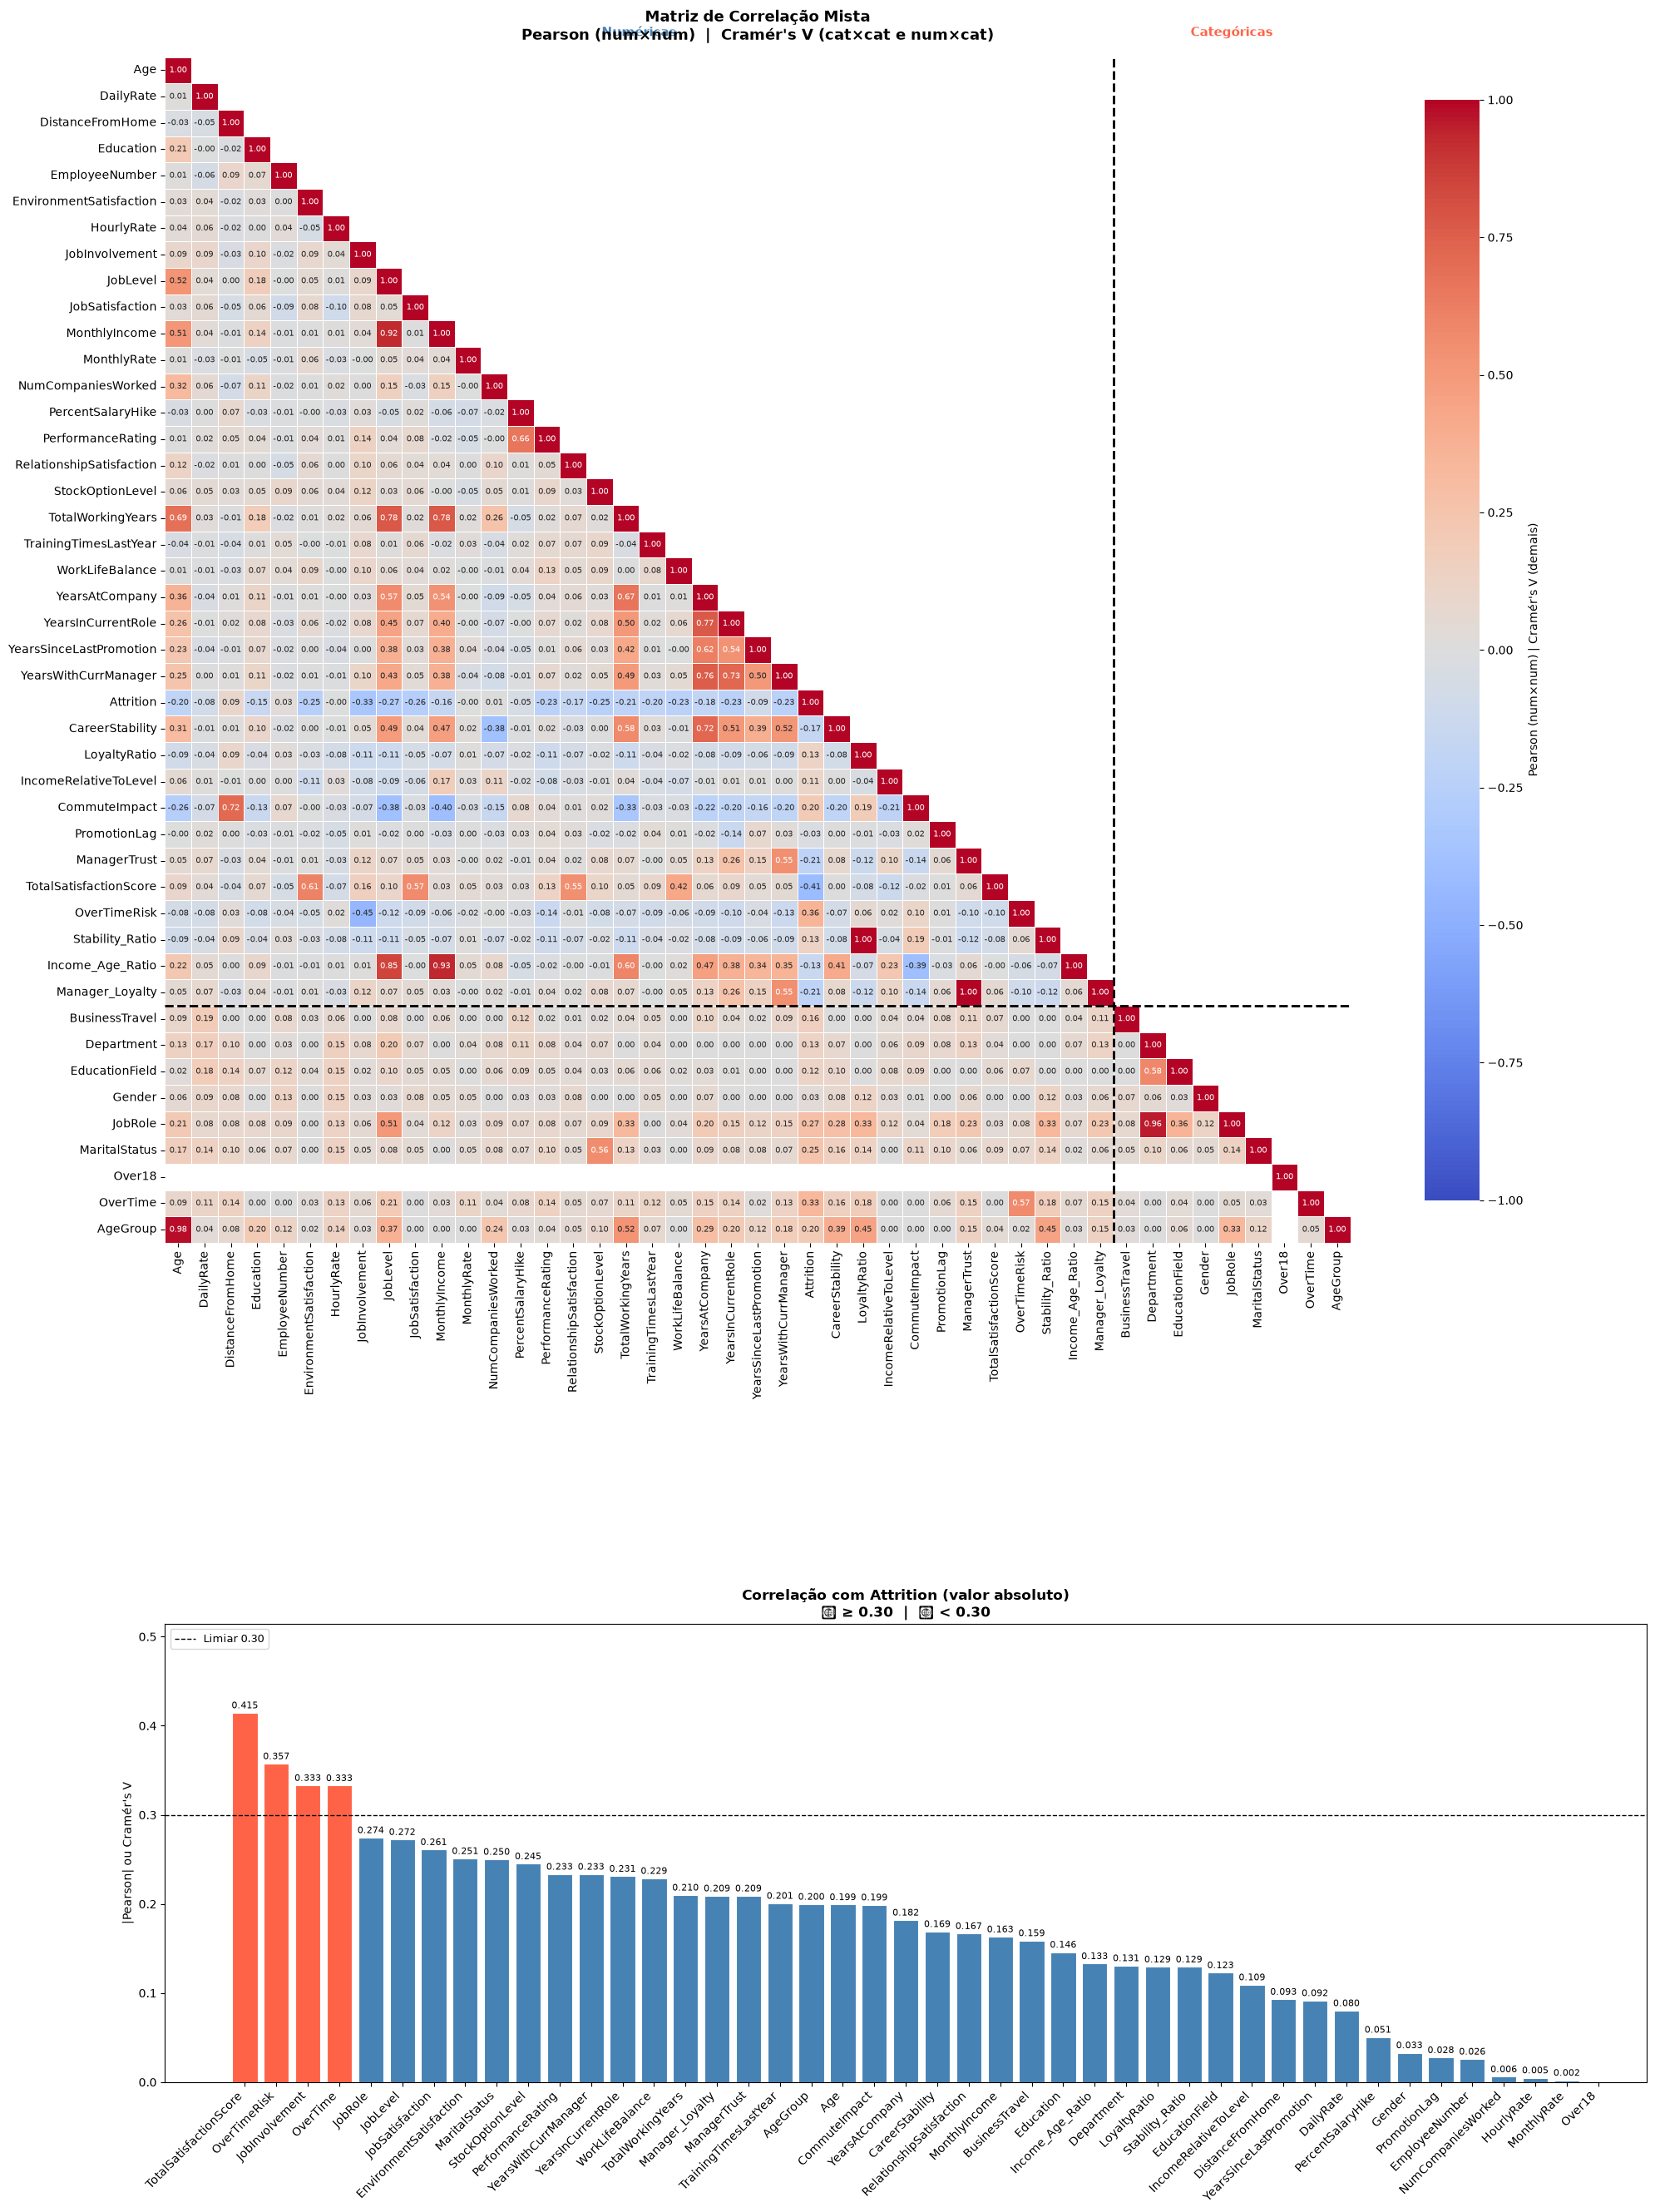


TOP CORRELAÇÕES COM ATTRITION
TotalSatisfactionScore      0.414594
OverTimeRisk                0.357441
JobInvolvement              0.333055
OverTime                    0.332832
JobRole                     0.274435
JobLevel                    0.272372
JobSatisfaction             0.261067
EnvironmentSatisfaction     0.251012
MaritalStatus               0.250162
StockOptionLevel            0.245164
PerformanceRating           0.233447
YearsWithCurrManager        0.233385
YearsInCurrentRole          0.231159
WorkLifeBalance             0.228730
TotalWorkingYears           0.210016
Manager_Loyalty             0.209088
ManagerTrust                0.209087
TrainingTimesLastYear       0.200772
AgeGroup                    0.199707
Age                         0.199262
CommuteImpact               0.198995
YearsAtCompany              0.181961
CareerStability             0.169098
RelationshipSatisfaction    0.166795
MonthlyIncome               0.163187
BusinessTravel              0.158879
Educati

In [61]:
# ================================================
# Matriz de Correlação Mista: Pearson + Cramér's V 
# Cramer's V para dados categóricos
# ================================================

num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
all_cols = num_cols + cat_cols

n = len(all_cols)
corr_matrix = pd.DataFrame(np.zeros((n, n)), index=all_cols, columns=all_cols)

for col_a in all_cols:
    for col_b in all_cols:

        a_is_num = col_a in num_cols
        b_is_num = col_b in num_cols

        if col_a == col_b:
            corr_matrix.loc[col_a, col_b] = 1.0

        elif a_is_num and b_is_num:
            corr_matrix.loc[col_a, col_b] = df_train[col_a].corr(df_train[col_b])

        else:
            v = cramers_v(df_train[col_a].astype(str), df_train[col_b].astype(str))
            corr_matrix.loc[col_a, col_b] = v
            corr_matrix.loc[col_b, col_a] = v

corr_matrix = corr_matrix.astype(float)

# ── Visualização: 2 linhas × 1 coluna ────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(20, 30),
                          gridspec_kw={'height_ratios': [4, 1]})

# ── Plot 1: Heatmap completo ──────────────────────────────────────────────
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    ax=axes[0],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt='.2f',
    annot_kws={'size': 7},
    linewidths=0.4,
    square=True,
    cbar_kws={'label': "Pearson (num×num) | Cramér's V (demais)", 'shrink': 0.6}
)

n_num = len(num_cols)
axes[0].axhline(n_num, color='black', linewidth=2, linestyle='--')
axes[0].axvline(n_num, color='black', linewidth=2, linestyle='--')

axes[0].text(n_num / 2, -0.8, 'Numéricas', ha='center',
             fontsize=11, fontweight='bold', color='steelblue')
axes[0].text(n_num + len(cat_cols) / 2, -0.8, 'Categóricas', ha='center',
             fontsize=11, fontweight='bold', color='tomato')

axes[0].set_title("Matriz de Correlação Mista\nPearson (num×num)  |  Cramér's V (cat×cat e num×cat)",
                   fontsize=13, fontweight='bold', pad=15)
axes[0].tick_params(axis='x', rotation=90)
axes[0].tick_params(axis='y', rotation=0)

# ── Plot 2: Ranking de correlação com Attrition ───────────────────────────
if 'Attrition' in all_cols:
    attrition_corr = (
        corr_matrix['Attrition']
        .drop('Attrition')
        .abs()
        .sort_values(ascending=False)
    )

    colors = ['tomato' if v >= 0.3 else 'steelblue' for v in attrition_corr.values]

    axes[1].bar(attrition_corr.index, attrition_corr.values,
                color=colors, edgecolor='white', linewidth=0.8)
    axes[1].axhline(0.3, color='black', linestyle='--',
                    linewidth=1, label='Limiar 0.30')

    for i, (feat, val) in enumerate(attrition_corr.items()):
        axes[1].text(i, val + 0.005, f'{val:.3f}',
                     ha='center', fontsize=8, color='black')

    axes[1].set_title("Correlação com Attrition (valor absoluto)\n🔴 ≥ 0.30  |  🔵 < 0.30",
                       fontsize=12, fontweight='bold')
    axes[1].set_ylabel("|Pearson| ou Cramér's V")
    axes[1].set_xticks(range(len(attrition_corr)))
    axes[1].set_xticklabels(attrition_corr.index, rotation=45, ha='right')
    axes[1].set_ylim(0, attrition_corr.max() + 0.1)
    axes[1].legend(fontsize=9)

plt.tight_layout(h_pad=4)
plt.show()

# --- Resumo textual ---
print(f"\n{'='*50}")
print("TOP CORRELAÇÕES COM ATTRITION")
print(f"{'='*50}")
print(attrition_corr.to_string())


In [66]:
import numpy as np
import pandas as pd

col_target = 'Attrition'
LIMIAR = 0.75

# features numéricas, sem o alvo
num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != col_target]

# matriz de correlação (absoluta)
corr = df_train[num_cols].corr().abs()

# pega só o triângulo superior para não repetir pares (A-B e B-A) nem a diagonal (A-A = 1)
triangulo_sup = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

# monta a lista de pares acima do limiar
pares_colineares = (
    triangulo_sup.stack()                       # vira série (feature1, feature2) -> corr
    .reset_index()
    .rename(columns={'level_0': 'Feature_1', 'level_1': 'Feature_2', 0: 'Correlacao'})
    .query('Correlacao >= @LIMIAR')
    .sort_values('Correlacao', ascending=False)
    .reset_index(drop=True)
)

pares_colineares


,Feature_1,Feature_2,Correlacao
0,ManagerTrust,Manager_Loyalty,1.000000
1,LoyaltyRatio,Stability_Ratio,1.000000
2,MonthlyIncome,Income_Age_Ratio,0.930215
3,JobLevel,MonthlyIncome,0.922731
4,JobLevel,Income_Age_Ratio,0.849602
5,JobLevel,TotalWorkingYears,0.779806
6,MonthlyIncome,TotalWorkingYears,0.775427
7,YearsAtCompany,YearsInCurrentRole,0.770130
8,YearsAtCompany,YearsWithCurrManager,0.758649


In [65]:
# correlação (absoluta) de cada feature com o alvo
# Attrition precisa estar numérico (0/1) para entrar no corr
if df_train[col_target].dtype == object:
    y_num = (df_train[col_target] == 'Yes').astype(int)
else:
    y_num = df_train[col_target].astype(int)

corr_com_alvo = df_train[num_cols].corrwith(y_num).abs()

# para cada par colinear, remove a de MENOR correlação com o alvo
colunas_multicolineares = set()
for _, row in pares_colineares.iterrows():
    f1, f2 = row['Feature_1'], row['Feature_2']
    corr1 = corr_com_alvo.get(f1, 0)
    corr2 = corr_com_alvo.get(f2, 0)
    # mantém a de maior correlação com o alvo, remove a menor
    colunas_multicolineares.add(f2 if corr1 >= corr2 else f1)

colunas_multicolineares = list(colunas_multicolineares)
colunas_multicolineares



['MonthlyIncome',
 'YearsAtCompany',
 'Stability_Ratio',
 'Income_Age_Ratio',
 'ManagerTrust',
 'TotalWorkingYears']

# 7.0 Feature Selection

- Seleção de features
- Eliminação de features com ruidos para o modelo

## 7.1 Filter method

In [68]:
# Remove variáveis com variância abaixo do threshold
selector = VarianceThreshold(threshold=0.01)
X_filtered = selector.fit_transform(df_train[train_num_attributes])

# Verificar variância manualmente
variances = df_train[train_num_attributes].var()
low_var_cols = variances[variances < 0.01].index.tolist()
print("Variáveis com variância quasi-zero:", low_var_cols)

Variáveis com variância quasi-zero: ['CommuteImpact']


In [82]:
# junta todas as fontes de features a remover e elimina duplicatas
drop_vars = list(set(
    low_var_cols
    + low_discrimination_train_num_univars
    + low_discrimination_train_cat_univars 
    + low_discrimination_train_num_bivars 
    + low_discrimination_train_cat_bivars
))

print(f"Total de features a remover: {len(drop_vars)}")
print(f"\nFeatures que serão removidas:\n{drop_vars}")


Total de features a remover: 12

Features que serão removidas:
['MonthlyRate', 'EmployeeNumber', 'PercentSalaryHike', 'BusinessTravel', 'Over18', 'EducationField', 'Gender', 'CommuteImpact', 'IncomeRelativeToLevel', 'HourlyRate', 'DistanceFromHome', 'NumCompaniesWorked']


## 7.2 Boruta

In [85]:
# preparacao dados
X = df_train.drop( columns='Attrition' )
y = df_train['Attrition'].apply( lambda x: 1 if x == 1 else 0 )

X_boruta = pd.get_dummies( X, prefix_sep='__SEP__' )

# algoritmo
rf_boruta = en.RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=42)

# boruta
boruta = BorutaPy( rf_boruta, 
                   n_estimators='auto',
                   verbose=2,
                   random_state=42
).fit( X_boruta.values, y.values )

# resultados
confirmed_boruta = X_boruta.columns[boruta.support_].tolist()
tentative_boruta = X_boruta.columns[boruta.support_weak_].tolist()
rejected_boruta = X_boruta.columns[~boruta.support_ & ~boruta.support_weak_].tolist()

# --- Reverter dummies para nome original
def to_original( col ):
    return col.split( '__SEP__' )[0] if '__SEP__' in col else col

confirmed_boruta = sorted( set( to_original( c ) for c in confirmed_boruta ) )
tentative_boruta = sorted( set( to_original( c ) for c in tentative_boruta ) )
rejected_boruta  = sorted( set( to_original( c ) for c in rejected_boruta ) )

# Categórica só é "rejeitada" se TODAS as suas dummies foram rejeitadas.
# Se ao menos uma dummy foi confirmada/tentativa, removemos a original da lista de rejeitadas.
rejected_boruta = [ c for c in rejected_boruta
                      if c not in confirmed_boruta and c not in tentative_boruta ]

print( f'Variaveis confirmadas (originais): {confirmed_boruta}' )
print( f'Variaveis tentativas (originais):  {tentative_boruta}' )
print( f'Variaveis rejeitadas (originais):  {rejected_boruta}' )


# --- 1) Filter Method
rejected_columns = ( drop_vars
                    + rejected_boruta )

Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	6 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	7 / 100
Confirmed: 	0
Tentative: 	67
Rejected: 	0
Iteration: 	8 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	9 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	10 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	11 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	12 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	13 / 100
Confirmed: 	29
Tentative: 	9
Rejected: 	29
Iteration: 	14 / 100
Confirmed: 	29
Tentative: 	8
Rejected: 	30
Iteration: 	15 / 100
Confirmed: 	29
Tentative: 	8
Rejected: 	30
Iteration: 	16 / 100
Confirmed: 	30
Tentative: 	7
Reject

In [86]:
# dropando as variaveis rejeitadas pelo boruta
df_train_cleaned = df_train.drop( columns=rejected_columns )
df_val_cleaned = df_val.drop(columns = rejected_columns)

## 7.3 RFE

In [88]:
from sklearn.feature_selection import RFE, RFECV
from sklearn.ensemble import RandomForestClassifier


# Preparação simplificada para o Boruta (Encoding Temporário)
X = df_train.drop(columns=['Attrition'])
y = df_train['Attrition'].apply(lambda x: 1 if x == 1 else 0)

X_rfe = pd.get_dummies(X)

# RFE com número fixo de features
rf_rfe = RandomForestClassifier(n_estimators=100, random_state=42)
rfe = RFE(estimator=rf_rfe, n_features_to_select=10, step=1)
rfe.fit(X_rfe, y)

features_selecionadas = X_rfe.columns[rfe.support_].tolist()
print("Features selecionadas pelo RFE:", features_selecionadas)

# RFECV: encontra automaticamente o número ótimo via cross-validation
rfecv = RFECV(
    estimator=rf_rfe,
    step=1,
    cv=5,
    scoring='roc_auc',
    min_features_to_select=5
)
rfecv.fit(X_rfe, y)

print(f"Número ótimo de features: {rfecv.n_features_}")
print("Features:", X_rfe.columns[rfecv.support_].tolist())

Features selecionadas pelo RFE: ['MonthlyIncome', 'PerformanceRating', 'StockOptionLevel', 'TotalWorkingYears', 'CareerStability', 'IncomeRelativeToLevel', 'CommuteImpact', 'TotalSatisfactionScore', 'OverTimeRisk', 'Income_Age_Ratio']
Número ótimo de features: 67
Features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CareerStability', 'LoyaltyRatio', 'IncomeRelativeToLevel', 'CommuteImpact', 'PromotionLag', 'ManagerTrust', 'TotalSatisfactionScore', 'OverTimeRisk', 'Stability_Ratio', 'Income_Age_Ratio', 'Manager_Loyalty', 'BusinessTravel_Non-Travel', 'BusinessTravel_Travel_Fre

# 7.0 Data Preparation

## 7.1 Normalização e Rescala de dados númericos

### 7.1.2 Teste de normalidade

### 7.1.3 Scalers

## 7.2 Encoders de dados categóricos

# 8.0 Machine Learning Modeling

# 9.0 Model Evaluation

# 10.0 Models Comparison